# Demo 04 — Model Evaluation & Cross-Validation

**Machine Learning with scikit-learn — Session 04**

รันตามสไลด์คาบ 4 — คาบที่สำคัญที่สุดของคอร์ส: เรียนรู้วิธี "วัดคะแนนอย่างซื่อสัตย์"
โมเดลวันนี้เป็น black box ได้ (เปิดกล่องจริงในคาบ 5-6) — วันนี้เราสนใจแค่ตัวเลขที่ออกมา

## Slide 4 — The exam analogy: watch memorization happen

KNN กับ k=1: จุดที่ใกล้ที่สุดของทุกจุดคือตัวมันเอง → ทาย train ถูก 100% เป็นเนื้อๆ

In [1]:
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

Xc, yc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)

knn1 = KNeighborsClassifier(n_neighbors=1).fit(Xtr, ytr)
print(f"k=1 : train={knn1.score(Xtr, ytr):.3f}  test={knn1.score(Xte, yte):.3f}")

knn13 = KNeighborsClassifier(n_neighbors=13).fit(Xtr, ytr)
print(f"k=13: train={knn13.score(Xtr, ytr):.3f}  test={knn13.score(Xte, yte):.3f}")

k=1 : train=1.000  test=0.937
k=13: train=0.939  test=0.944


ช่องว่าง train กับ test ของ k=1 คือ "คำโกหก" — คะแนนจำ (memorization) ไม่ใช่คะแนนเข้าใจ

## Slide 6 — Grow a tree, watch the gap open

ปล่อยต้นไม้โตขึ้นเรื่อย ๆ (max_depth 1→12) แล้วดู train กับ test แยกทางกันเมื่อไหร่

In [2]:
for depth in [1, 2, 3, 4, 6, 8, 12]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xtr, ytr)
    print(f"depth={depth:2d}  train={tree.score(Xtr, ytr):.3f}  test={tree.score(Xte, yte):.3f}")

depth= 1  train=0.923  test=0.923
depth= 2  train=0.958  test=0.909
depth= 3  train=0.977  test=0.944
depth= 4  train=0.988  test=0.944
depth= 6  train=0.998  test=0.937
depth= 8  train=1.000  test=0.923
depth=12  train=1.000  test=0.923


- depth 1-3: สองคะแนนขึ้นด้วยกัน = กำลังเรียนรู้
- depth 3-4: test ถึงจุดสูงสุด (0.944) = sweet spot
- depth 8+: train พุ่งเป็น 1.000 แต่ test ตก = เริ่มท่องจำผู้ป่วยรายคน (overfitting)

## Slide 7 — Your holdout score is a lottery ticket

ข้อมูลเล็ก + แบ่งครั้งเดียว = คะแนนขึ้นลงตามดวง: diabetes 442 แถว โมเดลเดิม โค้ดเดิม เปลี่ยนแค่ random_state

In [3]:
from sklearn.linear_model import LinearRegression

Xd, yd = load_diabetes(return_X_y=True)
for seed in range(10):
    a, b, c, d = train_test_split(Xd, yd, test_size=0.25, random_state=seed)
    print(f"random_state={seed}:  holdout R2 = {LinearRegression().fit(a, c).score(b, d):.3f}")

random_state=0:  holdout R2 = 0.359
random_state=1:  holdout R2 = 0.444
random_state=2:  holdout R2 = 0.443
random_state=3:  holdout R2 = 0.426
random_state=4:  holdout R2 = 0.467
random_state=5:  holdout R2 = 0.531
random_state=6:  holdout R2 = 0.441
random_state=7:  holdout R2 = 0.503
random_state=8:  holdout R2 = 0.459
random_state=9:  holdout R2 = 0.586


R² วิ่งตั้งแต่ 0.36 ถึง 0.59 — ถ้าเจ้านายถามว่าโมเดลดีแค่ไหน คุณจะตอบตัวไหน? 🎲

## Slide 8-9 — k-fold CV: every point takes a turn

In [4]:
from sklearn.model_selection import cross_val_score
import numpy as np

scores = cross_val_score(LinearRegression(), Xd, yd, cv=5)
print("fold scores:", scores.round(3))
print(f"mean {scores.mean():.3f} ± {scores.std():.3f}")

fold scores: [0.43  0.523 0.483 0.426 0.55 ]
mean 0.482 ± 0.049


0.482 ± 0.049 — นิ่งและซื่อสัตย์กว่า holdout เด้ง ๆ มาก

ข้อมูลทุกแถวได้เป็นทั้งครู (train) และผู้เข้าสอบ (validation) ครบหนึ่งรอบ

## Slide 10 — Regression metrics: MAE · RMSE · R²

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

a, b, c, d = train_test_split(Xd, yd, test_size=0.25, random_state=42)
lr = LinearRegression().fit(a, c)
yp = lr.predict(b)
print(f"MAE  = {mean_absolute_error(d, yp):.1f}   # พลาดเฉลี่ย ±41.5 คะแนนโรค")
print(f"RMSE = {np.sqrt(mean_squared_error(d, yp)):.1f}   # ลงโทษความพลาดใหญ่หนักกว่า")
print(f"R2   = {r2_score(d, yp):.3f}   # อธิบาย variance ได้ ~49%")

MAE  = 41.5   # พลาดเฉลี่ย ±41.5 คะแนนโรค
RMSE = 53.4   # ลงโทษความพลาดใหญ่หนักกว่า
R2   = 0.485   # อธิบาย variance ได้ ~49%


## Slide 11 — The confusion matrix: four cells of truth

กลับไป breast cancer — KNN บน test set 143 คน (positive = malignant เป็นเนื้อร้าย)

In [6]:
from sklearn.metrics import confusion_matrix

knn = KNeighborsClassifier().fit(Xtr, ytr)
yp = knn.predict(Xte)
cm = confusion_matrix(yte, yp)
print(cm)

[[47  6]
 [ 4 86]]


In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

print(f"accuracy  = {(yte == yp).mean():.3f}")
print(f"precision = {precision_score(yte, yp):.3f}   # ของกล้องเตือนที่ดัง 86 ครั้ง จริงกี่ครั้ง")
print(f"recall    = {recall_score(yte, yp):.3f}   # ของผู้ป่วยจริง 90 คน จับได้กี่คน")
print(f"f1        = {f1_score(yte, yp):.3f}")
print(f"roc-auc   = {roc_auc_score(yte, knn.predict_proba(Xte)[:, 1]):.3f}")

accuracy  = 0.930
precision = 0.935   # ของกล้องเตือนที่ดัง 86 ครั้ง จริงกี่ครั้ง
recall    = 0.956   # ของผู้ป่วยจริง 90 คน จับได้กี่คน
f1        = 0.945
roc-auc   = 0.962


- **6 false positives**: คนสุขภาพดีถูกส่งตรวจซ้ำ = เสียเงิน เสียความกลัว
- **4 false negatives**: ผู้ป่วยมะเร็งถูกบอกว่า "ปกติ" = เสียชีวิต

accuracy เพียงตัวเดียวบอกเราไม่ได้เลยว่าพลาด "แบบไหน"

## Slide 13 — ROC curve: judgment across ALL thresholds

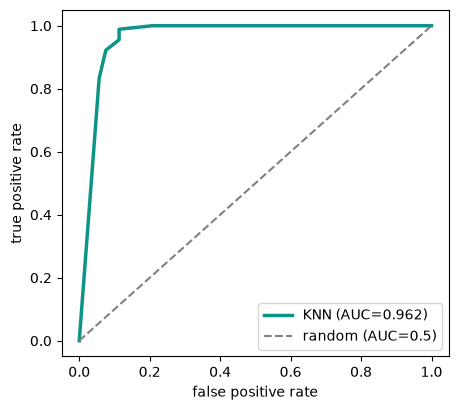

In [8]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

proba = knn.predict_proba(Xte)[:, 1]
fpr, tpr, _ = roc_curve(yte, proba)

plt.figure(figsize=(5, 4.5))
plt.plot(fpr, tpr, color="#0D9488", lw=2.5, label=f"KNN (AUC={roc_auc_score(yte, proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="random (AUC=0.5)")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.legend(); plt.show()

## Slide 14 — When accuracy lies: imbalanced data

จำลองข้อมูลเบ้: คงผู้ป่วย malignant ไว้หมด แต่เหลือ benign แค่ 14% → positive rate ~19% (เหมือน fraud/churn)

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

rng = np.random.RandomState(7)
malign = np.where(yc == 0)[0]
benign = np.where(yc == 1)[0]
keep = np.concatenate([malign, rng.choice(benign, size=int(len(benign) * 0.14), replace=False)])
Xi, yi = Xc[keep], yc[keep]

Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=42)

dumb = DummyClassifier(strategy="most_frequent").fit(Xi_tr, yi_tr)
p_dumb = dumb.predict(Xi_te)
print(f"Dummy (nobody is sick): acc={(p_dumb == yi_te).mean():.3f}  recall={recall_score(yi_te, p_dumb):.3f}")

knnb = KNeighborsClassifier().fit(Xi_tr, yi_tr)
p_knn = knnb.predict(Xi_te)
print(f"KNN                  : acc={(p_knn == yi_te).mean():.3f}  recall={recall_score(yi_te, p_knn):.3f}  f1={f1_score(yi_te, p_knn):.3f}")

rfw = RandomForestClassifier(random_state=42, class_weight="balanced").fit(Xi_tr, yi_tr)
p_rf = rfw.predict(Xi_te)
print(f"RF class_weight      : acc={(p_rf == yi_te).mean():.3f}  recall={recall_score(yi_te, p_rf):.3f}  f1={f1_score(yi_te, p_rf):.3f}")

Dummy (nobody is sick): acc=0.810  recall=0.000
KNN                  : acc=0.911  recall=0.867  f1=0.788
RF class_weight      : acc=0.937  recall=0.867  f1=0.839


Dummy ได้ accuracy 81% ทั้งที่จับผู้ป่วยได้ **0 คน** — accuracy โกหกกับข้อมูลเบนเสมอ
ทางแก้: เลือก metric ให้ถูก (recall/F1) · `class_weight="balanced"` · ขยับ threshold

## Slide 15-16 — Baselines + comparing models the honest way

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(5, shuffle=True, random_state=42)
models = [
    ("Dummy(stratified)", DummyClassifier(strategy="stratified", random_state=42)),
    ("Dummy(most_freq)",  DummyClassifier(strategy="most_frequent")),
    ("KNN(k=5)",          KNeighborsClassifier()),
    ("RandomForest(100)", RandomForestClassifier(random_state=42)),
]
for name, m in models:
    acc = cross_val_score(m, Xc, yc, cv=skf).mean()
    auc = cross_val_score(m, Xc, yc, cv=skf, scoring="roc_auc").mean()
    print(f"{name:20s} CV acc={acc:.3f}  CV AUC={auc:.3f}")

Dummy(stratified)    CV acc=0.576  CV AUC=0.536
Dummy(most_freq)     CV acc=0.627  CV AUC=0.500


KNN(k=5)             CV acc=0.935  CV AUC=0.966


RandomForest(100)    CV acc=0.956  CV AUC=0.989


กติกา 3 ข้อที่ฝังอยู่ใน cell เดียวกันนี้: **fold เดียวกันทุกโมเดล** (skf) · **หลาย metric** · **มี Dummy เป็นตัวเทียบ**

## Slide 17 — The protocol for the rest of the course

- **CV ใช้ตัดสินใจ** (โมเดลไหน? k เท่าไหร่? ฟีเจอร์ชุดไหน?) — ทำบน train เท่านั้น
- **test ใช้ตอบคำถามสุดท้าย** ครั้งเดียว ตอนจบโปรเจ็ค

---
✅ **จบ Demo 04** — ต่อไป: **Lab 04** ใน `excercises/04.evaluation_cv_exercise.ipynb` (ทำซ้ำทุกการทดลองของวันนี้ด้วยมือตัวเอง)